In [1]:

# Import các thư viện cần thiết

import pandas as pd
import numpy as np
import os
import joblib

# Cố định random seed
RANDOM_SEED = 42

# Hiển thị đầy đủ cột
pd.set_option("display.max_columns", None)

print("Đã import thư viện thành công!")


Đã import thư viện thành công!


In [2]:

# Đọc dữ liệu từ UCI
url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/00468/"
    "online_shoppers_intention.csv"
)

df = pd.read_csv(url)

print("Kích thước ban đầu:", df.shape)

# Loại bỏ các bản ghi trùng
df_clean = df.drop_duplicates().copy()

print("Số bản ghi trùng đã loại:", len(df) - len(df_clean))
print("Kích thước sau khi làm sạch:", df_clean.shape)

# Kiểm tra dữ liệu
print("\nSố giá trị thiếu:")
print(df_clean.isnull().sum().sum())

print("\nPhân bố biến Revenue:")
print(df_clean["Revenue"].value_counts())
print(df_clean["Revenue"].value_counts(normalize=True) * 100)


Kích thước ban đầu: (12330, 18)
Số bản ghi trùng đã loại: 125
Kích thước sau khi làm sạch: (12205, 18)

Số giá trị thiếu:
0

Phân bố biến Revenue:
Revenue
False    10297
True      1908
Name: count, dtype: int64
Revenue
False    84.367063
True     15.632937
Name: proportion, dtype: float64


In [3]:

from sklearn.model_selection import train_test_split

# X: Các đặc trưng đầu vào
X = df_clean.drop(columns=["Revenue"])

# y: Biến mục tiêu
y = df_clean["Revenue"].astype(int)

print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)


Kích thước X: (12205, 17)
Kích thước y: (12205,)


In [4]:

# Chia 70% Train và 30% còn lại
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_SEED,
    stratify=y
)

# Chia phần 30% thành Validation 15% và Test 15%
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_SEED,
    stratify=y_temp
)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)


Train: (8543, 17) (8543,)
Validation: (1831, 17) (1831,)
Test: (1831, 17) (1831,)


In [5]:

def check_distribution(name, target):
    print(f"\n{name}")
    print("Số lượng:")
    print(target.value_counts().sort_index())

    print("Tỷ lệ (%):")
    print(
        (target.value_counts(normalize=True)
         .sort_index() * 100).round(2)
    )

check_distribution("TRAIN", y_train)
check_distribution("VALIDATION", y_val)
check_distribution("TEST", y_test)



TRAIN
Số lượng:
Revenue
0    7207
1    1336
Name: count, dtype: int64
Tỷ lệ (%):
Revenue
0    84.36
1    15.64
Name: proportion, dtype: float64

VALIDATION
Số lượng:
Revenue
0    1545
1     286
Name: count, dtype: int64
Tỷ lệ (%):
Revenue
0    84.38
1    15.62
Name: proportion, dtype: float64

TEST
Số lượng:
Revenue
0    1545
1     286
Name: count, dtype: int64
Tỷ lệ (%):
Revenue
0    84.38
1    15.62
Name: proportion, dtype: float64


In [6]:

# Tạo thư mục lưu dữ liệu
os.makedirs("data/splits", exist_ok=True)

# Lưu từng tập, bao gồm cả biến mục tiêu
train_data = X_train.copy()
train_data["Revenue"] = y_train

val_data = X_val.copy()
val_data["Revenue"] = y_val

test_data = X_test.copy()
test_data["Revenue"] = y_test

train_data.to_csv("data/splits/train.csv", index=False)
val_data.to_csv("data/splits/validation.csv", index=False)
test_data.to_csv("data/splits/test.csv", index=False)

print("Đã lưu thành công 3 tập dữ liệu!")


Đã lưu thành công 3 tập dữ liệu!


In [7]:

# Xác định các cột phân loại
categorical_features = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

# Các cột còn lại là đặc trưng số
numeric_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

print("Đặc trưng số:")
print(numeric_features)

print("\nĐặc trưng phân loại:")
print(categorical_features)


Đặc trưng số:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']

Đặc trưng phân loại:
['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']


In [8]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Pipeline cho đặc trưng số
numeric_transformer_lr = Pipeline(steps=[
    ("scaler", StandardScaler())
])

# Pipeline cho đặc trưng phân loại
categorical_transformer = Pipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Kết hợp hai nhóm đặc trưng
preprocessor_lr = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_lr, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Đã tạo Pipeline tiền xử lý cho Logistic Regression!")


Đã tạo Pipeline tiền xử lý cho Logistic Regression!


In [9]:

# Cây quyết định và rừng ngẫu nhiên không cần chuẩn hóa
numeric_transformer_tree = "passthrough"

preprocessor_tree = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_tree, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Đã tạo Pipeline tiền xử lý cho mô hình cây!")


Đã tạo Pipeline tiền xử lý cho mô hình cây!


In [10]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

print("Đã import 3 thuật toán thành công!")

Đã import 3 thuật toán thành công!


In [11]:

# 1. Logistic Regression
lr_model = Pipeline(steps=[
    ("preprocessor", preprocessor_lr),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_SEED
    ))
])

# 2. Decision Tree
dt_model = Pipeline(steps=[
    ("preprocessor", preprocessor_tree),
    ("classifier", DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=10,
        min_samples_leaf=5,
        random_state=RANDOM_SEED
    ))
])

# 3. Random Forest
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor_tree),
    ("classifier", RandomForestClassifier(
        class_weight="balanced",
        n_estimators=300,
        max_depth=None,
        n_jobs=-1,
        random_state=RANDOM_SEED
    ))
])

# Tập hợp các mô hình
models = {
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}

print("Đã khởi tạo thành công 3 mô hình!")

Đã khởi tạo thành công 3 mô hình!


In [12]:

# Huấn luyện từng mô hình trên tập Train

for name, model in models.items():
    print(f"Đang huấn luyện: {name}")

    model.fit(X_train, y_train)

    print(f"Đã huấn luyện xong: {name}\n")

print("HOÀN THÀNH HUẤN LUYỆN 3 MÔ HÌNH!")

Đang huấn luyện: Logistic Regression
Đã huấn luyện xong: Logistic Regression

Đang huấn luyện: Decision Tree
Đã huấn luyện xong: Decision Tree

Đang huấn luyện: Random Forest
Đã huấn luyện xong: Random Forest

HOÀN THÀNH HUẤN LUYỆN 3 MÔ HÌNH!


In [13]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

initial_results = []

for name, model in models.items():

    # Dự đoán xác suất mua hàng trên Validation
    y_val_proba = model.predict_proba(X_val)[:, 1]

    # Dự đoán nhãn với ngưỡng 0.5
    y_val_pred = (y_val_proba >= 0.5).astype(int)

    initial_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_val_pred),
        "Precision": precision_score(
            y_val, y_val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_val_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, y_val_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, y_val_proba),
        "PR-AUC": average_precision_score(y_val, y_val_proba)
    })

initial_results_df = pd.DataFrame(initial_results)

display(
    initial_results_df.round(4)
)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.8427,0.4978,0.7762,0.6066,0.9021,0.6831
1,Decision Tree,0.8411,0.4944,0.7727,0.6030,0.8556,0.6461
2,Random Forest,0.8962,0.7553,0.4965,0.5992,0.9211,0.7244


In [14]:

os.makedirs("results", exist_ok=True)

initial_results_df.to_csv(
    "results/initial_model_results.csv",
    index=False
)

print("Đã lưu kết quả đánh giá sơ bộ!")

Đã lưu kết quả đánh giá sơ bộ!


In [15]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold

print("Đã import thư viện tối ưu siêu tham số!")


Đã import thư viện tối ưu siêu tham số!


In [16]:

# Chia tập Train thành 5 phần,
# giữ tỷ lệ lớp Revenue tương đương giữa các folds

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_SEED
)

print("Đã thiết lập Stratified 5-Fold Cross Validation!")


Đã thiết lập Stratified 5-Fold Cross Validation!


In [17]:

lr_param_grid = {
    "classifier__C": [0.1, 1, 10]
}

lr_search = GridSearchCV(
    estimator=lr_model,
    param_grid=lr_param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

lr_search.fit(X_train, y_train)

print("Tham số tốt nhất:", lr_search.best_params_)
print("PR-AUC tốt nhất:", lr_search.best_score_)


Fitting 5 folds for each of 3 candidates, totalling 15 fits
Tham số tốt nhất: {'classifier__C': 0.1}
PR-AUC tốt nhất: 0.6484430482931212


In [18]:

dt_param_grid = {
    "classifier__max_depth": [5, 10, 15, None],
    "classifier__min_samples_leaf": [2, 5, 10]
}

dt_search = GridSearchCV(
    estimator=dt_model,
    param_grid=dt_param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

dt_search.fit(X_train, y_train)

print("Tham số tốt nhất:", dt_search.best_params_)
print("PR-AUC tốt nhất:", dt_search.best_score_)


Fitting 5 folds for each of 12 candidates, totalling 60 fits
Tham số tốt nhất: {'classifier__max_depth': 5, 'classifier__min_samples_leaf': 5}
PR-AUC tốt nhất: 0.68517984973867


In [20]:

rf_param_grid = {
    "classifier__n_estimators": [200, 300],
    "classifier__max_depth": [None, 15],
    "classifier__min_samples_leaf": [1, 3]
}

rf_search = GridSearchCV(
    estimator=rf_model,
    param_grid=rf_param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=1,
    refit=True,
    verbose=1
)

rf_search.fit(X_train, y_train)

print("Tham số tốt nhất:", rf_search.best_params_)
print("PR-AUC tốt nhất:", rf_search.best_score_)


Fitting 5 folds for each of 8 candidates, totalling 40 fits
Tham số tốt nhất: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 300}
PR-AUC tốt nhất: 0.7435341523861286


In [22]:

# Lưu các mô hình đã tối ưu
best_models = {
    "Logistic Regression": lr_search.best_estimator_,
    "Decision Tree": dt_search.best_estimator_,
    "Random Forest": rf_search.best_estimator_
}

# Tổng hợp kết quả Cross Validation
tuning_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Best Parameters": str(lr_search.best_params_),
        "Best CV PR-AUC": lr_search.best_score_
    },
    {
        "Model": "Decision Tree",
        "Best Parameters": str(dt_search.best_params_),
        "Best CV PR-AUC": dt_search.best_score_
    },
    {
        "Model": "Random Forest",
        "Best Parameters": str(rf_search.best_params_),
        "Best CV PR-AUC": rf_search.best_score_
    }
])

display(tuning_results.round(4))

# Lưu kết quả
os.makedirs("results", exist_ok=True)

tuning_results.to_csv(
    "results/hyperparameter_tuning.csv",
    index=False
)

print("Đã lưu kết quả tối ưu siêu tham số!")


,Model,Best Parameters,Best CV PR-AUC
0,Logistic Regression,{'classifier__C': 0.1},0.6484
1,Decision Tree,"{'classifier__max_depth': 5, 'classifier__min_...",0.6852
2,Random Forest,"{'classifier__max_depth': None, 'classifier__m...",0.7435


Đã lưu kết quả tối ưu siêu tham số!


In [23]:

models = best_models.copy()

print("Đã cập nhật 3 mô hình bằng cấu hình tối ưu!")


Đã cập nhật 3 mô hình bằng cấu hình tối ưu!


In [24]:

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

print("Đã import thư viện đánh giá mô hình!")


Đã import thư viện đánh giá mô hình!


In [25]:

# Lưu ngưỡng tối ưu của từng mô hình
best_thresholds = {}

# Lưu kết quả lựa chọn ngưỡng
threshold_results = []

for name, model in best_models.items():

    # Dự đoán xác suất mua hàng trên Validation
    y_val_proba = model.predict_proba(X_val)[:, 1]

    # Tính đường Precision-Recall
    precision, recall, thresholds = precision_recall_curve(
        y_val,
        y_val_proba
    )

    # Tính F1 cho từng ngưỡng
    f1_scores = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-10)
    )

    # Tìm ngưỡng có F1 cao nhất
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx]

    # Lưu ngưỡng
    best_thresholds[name] = best_threshold

    threshold_results.append({
        "Model": name,
        "Best Threshold": best_threshold,
        "Validation Precision": precision[best_idx],
        "Validation Recall": recall[best_idx],
        "Validation F1": f1_scores[best_idx],
        "Validation PR-AUC": average_precision_score(
            y_val, y_val_proba
        )
    })

threshold_results_df = pd.DataFrame(threshold_results)

display(threshold_results_df.round(4))


,Model,Best Threshold,Validation Precision,Validation Recall,Validation F1,Validation PR-AUC
0,Logistic Regression,0.5926,0.6068,0.6853,0.6437,0.6849
1,Decision Tree,0.7295,0.6508,0.7168,0.6822,0.6829
2,Random Forest,0.3233,0.6447,0.7168,0.6788,0.7244


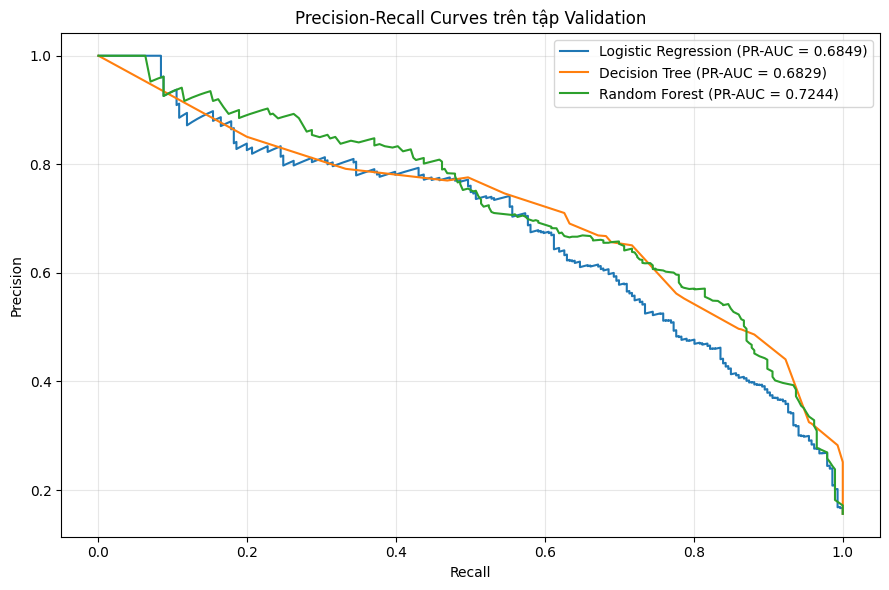

In [26]:

plt.figure(figsize=(9, 6))

for name, model in best_models.items():

    y_val_proba = model.predict_proba(X_val)[:, 1]

    precision, recall, _ = precision_recall_curve(
        y_val, y_val_proba
    )

    pr_auc = average_precision_score(
        y_val, y_val_proba
    )

    plt.plot(
        recall,
        precision,
        label=f"{name} (PR-AUC = {pr_auc:.4f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves trên tập Validation")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

os.makedirs("results/figures", exist_ok=True)

plt.savefig(
    "results/figures/precision_recall_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [27]:

# Lưu kết quả ngưỡng tối ưu
threshold_results_df.to_csv(
    "results/optimal_thresholds.csv",
    index=False
)

print("Đã lưu ngưỡng tối ưu của 3 mô hình!")
print(best_thresholds)


Đã lưu ngưỡng tối ưu của 3 mô hình!
{'Logistic Regression': np.float64(0.5925827514997453), 'Decision Tree': np.float64(0.7295272800890774), 'Random Forest': np.float64(0.3233333333333333)}


In [28]:

test_results = []
test_predictions = {}

for name, model in best_models.items():

    # Dự đoán xác suất trên Test
    y_test_proba = model.predict_proba(X_test)[:, 1]

    # Lấy ngưỡng đã chọn từ Validation
    threshold = best_thresholds[name]

    # Chuyển xác suất thành nhãn
    y_test_pred = (
        y_test_proba >= threshold
    ).astype(int)

    # Lưu dự đoán
    test_predictions[name] = y_test_pred

    # Tính các chỉ số
    test_results.append({
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_test_pred),
        "Precision": precision_score(
            y_test, y_test_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_test_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_test_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, y_test_proba
        ),
        "PR-AUC": average_precision_score(
            y_test, y_test_proba
        )
    })

test_results_df = pd.DataFrame(test_results)

display(test_results_df.round(4))


,Model,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.5926,0.8782,0.5957,0.6853,0.6374,0.8951,0.6258
1,Decision Tree,0.7295,0.8940,0.6438,0.7203,0.6799,0.9165,0.6719
2,Random Forest,0.3233,0.8902,0.6269,0.7343,0.6763,0.9205,0.7247


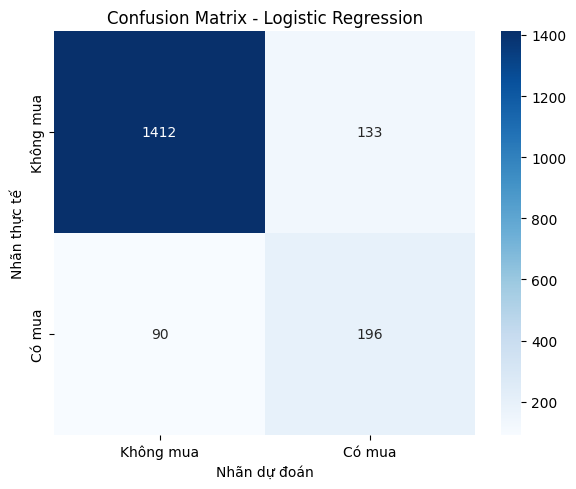

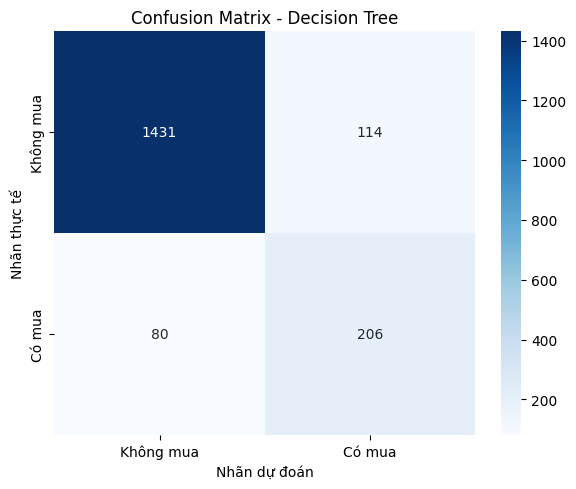

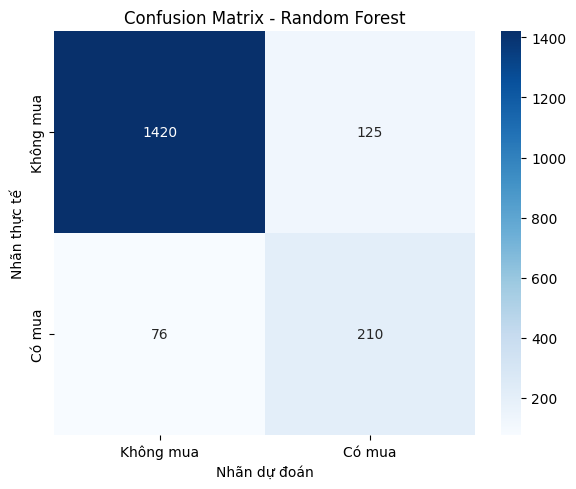

In [29]:

for name, y_test_pred in test_predictions.items():

    cm = confusion_matrix(y_test, y_test_pred)

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Không mua", "Có mua"],
        yticklabels=["Không mua", "Có mua"]
    )

    plt.xlabel("Nhãn dự đoán")
    plt.ylabel("Nhãn thực tế")
    plt.title(f"Confusion Matrix - {name}")

    plt.tight_layout()

    safe_name = name.lower().replace(" ", "_")

    plt.savefig(
        f"results/figures/confusion_matrix_{safe_name}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


In [30]:

# Lưu bảng đánh giá cuối cùng
test_results_df.to_csv(
    "results/test_metrics.csv",
    index=False
)

# Lưu dự đoán trên tập Test
test_predictions_df = pd.DataFrame({
    "Actual": y_test.to_numpy()
})

for name, predictions in test_predictions.items():
    safe_name = name.lower().replace(" ", "_")
    test_predictions_df[safe_name] = predictions

test_predictions_df.to_csv(
    "results/test_predictions.csv",
    index=False
)

print("Đã lưu toàn bộ kết quả đánh giá Test!")


Đã lưu toàn bộ kết quả đánh giá Test!


In [31]:

!pip install shap -q

import shap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

print("Phiên bản SHAP:", shap.__version__)
print("Đã import SHAP thành công!")


Phiên bản SHAP: 0.54.1
Đã import SHAP thành công!


In [32]:

# Lấy mô hình Random Forest đã tối ưu
best_rf_pipeline = best_models["Random Forest"]

# Tách bộ tiền xử lý và thuật toán
rf_preprocessor = best_rf_pipeline.named_steps["preprocessor"]
rf_classifier = best_rf_pipeline.named_steps["classifier"]

print("Đã lấy mô hình Random Forest tối ưu!")


Đã lấy mô hình Random Forest tối ưu!


In [33]:

# Lấy tên các đặc trưng sau One-hot Encoding
feature_names = rf_preprocessor.get_feature_names_out()

print("Tổng số đặc trưng sau tiền xử lý:", len(feature_names))
print("\nDanh sách đặc trưng:")
print(feature_names)


Tổng số đặc trưng sau tiền xử lý: 74

Danh sách đặc trưng:
['num__Administrative' 'num__Administrative_Duration' 'num__Informational'
 'num__Informational_Duration' 'num__ProductRelated'
 'num__ProductRelated_Duration' 'num__BounceRates' 'num__ExitRates'
 'num__PageValues' 'num__SpecialDay' 'cat__Month_Aug' 'cat__Month_Dec'
 'cat__Month_Feb' 'cat__Month_Jul' 'cat__Month_June' 'cat__Month_Mar'
 'cat__Month_May' 'cat__Month_Nov' 'cat__Month_Oct' 'cat__Month_Sep'
 'cat__OperatingSystems_1' 'cat__OperatingSystems_2'
 'cat__OperatingSystems_3' 'cat__OperatingSystems_4'
 'cat__OperatingSystems_5' 'cat__OperatingSystems_6'
 'cat__OperatingSystems_7' 'cat__OperatingSystems_8' 'cat__Browser_1'
 'cat__Browser_2' 'cat__Browser_3' 'cat__Browser_4' 'cat__Browser_5'
 'cat__Browser_6' 'cat__Browser_7' 'cat__Browser_8' 'cat__Browser_9'
 'cat__Browser_10' 'cat__Browser_11' 'cat__Browser_12' 'cat__Browser_13'
 'cat__Region_1' 'cat__Region_2' 'cat__Region_3' 'cat__Region_4'
 'cat__Region_5' 'cat__Region_

In [34]:

# Lấy độ quan trọng của từng đặc trưng từ Random Forest
importance_values = rf_classifier.feature_importances_

# Tạo bảng Feature Importance
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sắp xếp từ cao xuống thấp
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Hiển thị Top 15
display(feature_importance_df.head(15).round(5))


,Feature,Importance
0,num__PageValues,0.32262
1,num__ExitRates,0.09950
2,num__ProductRelated_Duration,0.07920
3,num__ProductRelated,0.06647
4,num__BounceRates,0.05306
5,num__Administrative_Duration,0.04931
6,num__Administrative,0.04081
7,cat__Month_Nov,0.02392
8,num__Informational_Duration,0.02237
9,num__Informational,0.01532


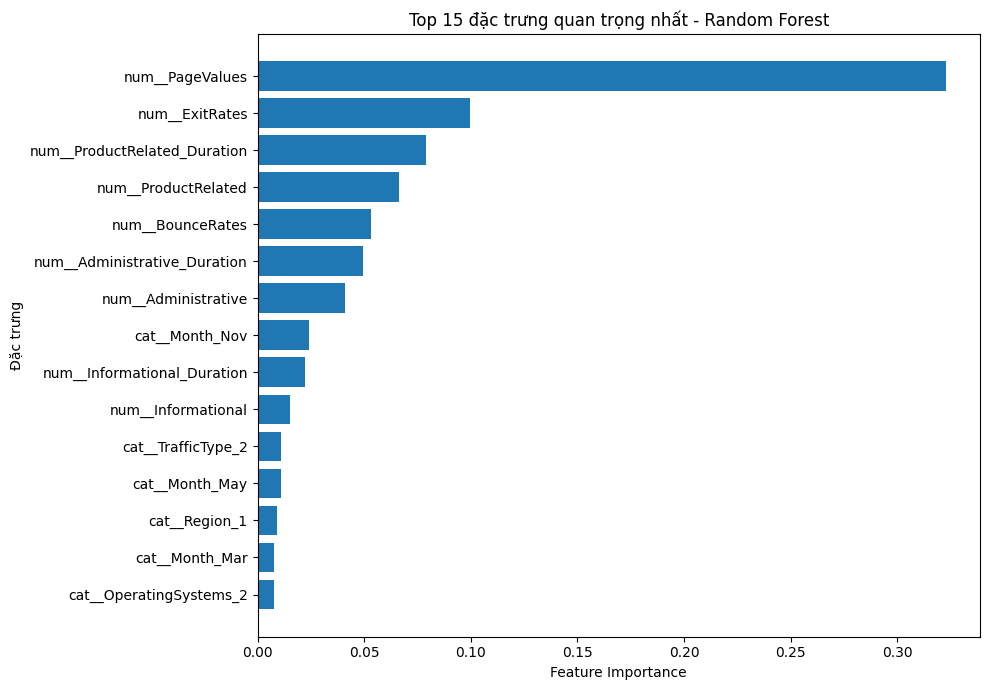

In [35]:

top_features = feature_importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Đặc trưng")
plt.title("Top 15 đặc trưng quan trọng nhất - Random Forest")

plt.tight_layout()

os.makedirs("results/figures", exist_ok=True)

plt.savefig(
    "results/figures/random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [36]:

feature_importance_df.to_csv(
    "results/feature_importance.csv",
    index=False
)

print("Đã lưu Feature Importance thành công!")


Đã lưu Feature Importance thành công!


In [37]:

# Biến đổi dữ liệu bằng đúng bộ tiền xử lý đã fit trên Train
X_train_transformed = rf_preprocessor.transform(X_train)
X_test_transformed = rf_preprocessor.transform(X_test)

# Chuyển sang mảng dense nếu dữ liệu đang ở dạng sparse
if hasattr(X_train_transformed, "toarray"):
    X_train_transformed = X_train_transformed.toarray()

if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

# Lấy tên đặc trưng
X_test_shap = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index
)

# Lấy tối đa 100 phiên làm dữ liệu nền
background = shap.sample(
    X_train_transformed,
    min(100, len(X_train_transformed)),
    random_state=RANDOM_SEED
)

# Lấy tối đa 100 phiên để giải thích
X_explain = X_test_shap.iloc[
    :min(100, len(X_test_shap))
]

print("Kích thước dữ liệu nền:", background.shape)
print("Kích thước dữ liệu giải thích:", X_explain.shape)


Kích thước dữ liệu nền: (100, 74)
Kích thước dữ liệu giải thích: (100, 74)


In [38]:

# Tạo TreeExplainer cho Random Forest
explainer = shap.TreeExplainer(
    rf_classifier,
    data=background,
    model_output="probability",
    feature_perturbation="interventional"
)

# Tính SHAP Values
shap_values = explainer.shap_values(X_explain)

print("Đã tính SHAP Values thành công!")


 97%|=================== | 194/200 [00:40<00:01]       

Đã tính SHAP Values thành công!


In [39]:

# Xử lý định dạng SHAP khác nhau giữa các phiên bản
if isinstance(shap_values, list):
    # Một số phiên bản trả về danh sách cho từng lớp
    shap_purchase = np.asarray(shap_values[1])
else:
    shap_array = np.asarray(shap_values)

    if shap_array.ndim == 3:
        # Dạng (số phiên, số đặc trưng, số lớp)
        shap_purchase = shap_array[:, :, 1]
    else:
        # Dạng (số phiên, số đặc trưng)
        shap_purchase = shap_array

print("Kích thước SHAP:", shap_purchase.shape)
print("Kích thước dữ liệu:", X_explain.shape)


Kích thước SHAP: (100, 74)
Kích thước dữ liệu: (100, 74)


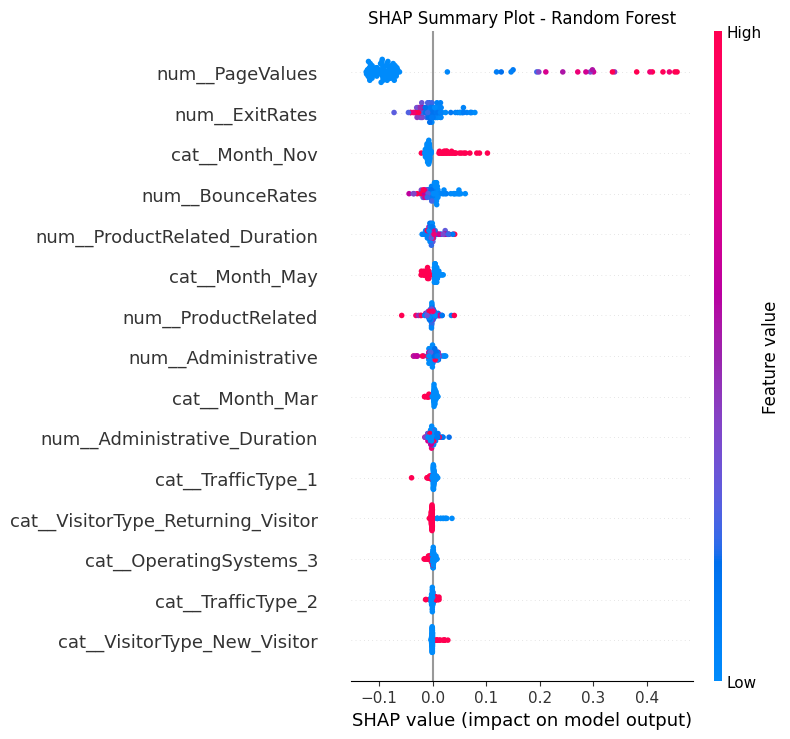

In [40]:

shap.summary_plot(
    shap_purchase,
    X_explain,
    max_display=15,
    show=False
)

plt.title("SHAP Summary Plot - Random Forest")
plt.tight_layout()

plt.savefig(
    "results/figures/shap_summary_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [41]:

shap_explanation_rows = []

for i in range(len(X_explain)):

    # Sắp xếp đặc trưng theo mức đóng góp tuyệt đối
    top_indices = np.argsort(
        np.abs(shap_purchase[i])
    )[::-1][:3]

    for rank, feature_idx in enumerate(top_indices, start=1):

        shap_value = shap_purchase[i, feature_idx]

        shap_explanation_rows.append({
            "Session_Index": X_explain.index[i],
            "Rank": rank,
            "Feature": feature_names[feature_idx],
            "SHAP_Value": shap_value,
            "Impact": (
                "Tăng khả năng mua hàng"
                if shap_value > 0
                else "Giảm khả năng mua hàng"
                if shap_value < 0
                else "Ảnh hưởng gần như bằng 0"
            )
        })

shap_top3_df = pd.DataFrame(shap_explanation_rows)

display(shap_top3_df.head(15).round(5))


,Session_Index,Rank,Feature,SHAP_Value,Impact
0,2345,1,num__PageValues,-0.08638,Giảm khả năng mua hàng
1,2345,2,num__ExitRates,-0.02784,Giảm khả năng mua hàng
2,2345,3,cat__Month_May,-0.01040,Giảm khả năng mua hàng
3,251,1,num__PageValues,-0.09479,Giảm khả năng mua hàng
4,251,2,num__ExitRates,-0.02981,Giảm khả năng mua hàng
5,251,3,num__ProductRelated_Duration,0.01056,Tăng khả năng mua hàng
6,9251,1,num__PageValues,-0.07569,Giảm khả năng mua hàng
7,9251,2,cat__Month_Nov,-0.01353,Giảm khả năng mua hàng
8,9251,3,num__BounceRates,-0.00847,Giảm khả năng mua hàng
9,698,1,num__PageValues,-0.08146,Giảm khả năng mua hàng


In [42]:

shap_top3_df.to_csv(
    "results/shap_top3_explanations.csv",
    index=False
)

print("Đã lưu Top 3 đặc trưng SHAP cho từng phiên!")


Đã lưu Top 3 đặc trưng SHAP cho từng phiên!


In [43]:

os.makedirs("results/models", exist_ok=True)

for name, model in best_models.items():

    filename = (
        name.lower().replace(" ", "_") + ".joblib"
    )

    joblib.dump(
        model,
        f"results/models/{filename}"
    )

    print("Đã lưu:", filename)


Đã lưu: logistic_regression.joblib
Đã lưu: decision_tree.joblib
Đã lưu: random_forest.joblib


In [44]:

experiment_rows = []

for _, row in test_results_df.iterrows():

    name = row["Model"]

    # Lấy cấu hình tốt nhất
    if name == "Logistic Regression":
        params = lr_search.best_params_
    elif name == "Decision Tree":
        params = dt_search.best_params_
    else:
        params = rf_search.best_params_

    # Lấy kết quả Validation tương ứng
    val_row = threshold_results_df[
        threshold_results_df["Model"] == name
    ].iloc[0]

    experiment_rows.append({
        "Model": name,
        "Best_Parameters": str(params),
        "Random_Seed": RANDOM_SEED,
        "Threshold": row["Threshold"],
        "Validation_PR_AUC": val_row["Validation PR-AUC"],
        "Validation_F1": val_row["Validation F1"],
        "Test_Accuracy": row["Accuracy"],
        "Test_Precision": row["Precision"],
        "Test_Recall": row["Recall"],
        "Test_F1": row["F1-score"],
        "Test_ROC_AUC": row["ROC-AUC"],
        "Test_PR_AUC": row["PR-AUC"]
    })

experiments_df = pd.DataFrame(experiment_rows)

experiments_df.to_csv(
    "results/experiments.csv",
    index=False
)

display(experiments_df.round(4))

print("Đã lưu nhật ký thí nghiệm!")


,Model,Best_Parameters,Random_Seed,Threshold,Validation_PR_AUC,Validation_F1,Test_Accuracy,Test_Precision,Test_Recall,Test_F1,Test_ROC_AUC,Test_PR_AUC
0,Logistic Regression,{'classifier__C': 0.1},42,0.5926,0.6849,0.6437,0.8782,0.5957,0.6853,0.6374,0.8951,0.6258
1,Decision Tree,"{'classifier__max_depth': 5, 'classifier__min_...",42,0.7295,0.6829,0.6822,0.8940,0.6438,0.7203,0.6799,0.9165,0.6719
2,Random Forest,"{'classifier__max_depth': None, 'classifier__m...",42,0.3233,0.7244,0.6788,0.8902,0.6269,0.7343,0.6763,0.9205,0.7247


Đã lưu nhật ký thí nghiệm!


In [45]:

print("DANH SÁCH FILE TRONG RESULTS:")

for root, dirs, files in os.walk("results"):
    for file in sorted(files):
        print(os.path.join(root, file))


DANH SÁCH FILE TRONG RESULTS:
results/experiments.csv
results/feature_importance.csv
results/hyperparameter_tuning.csv
results/initial_model_results.csv
results/optimal_thresholds.csv
results/shap_top3_explanations.csv
results/test_metrics.csv
results/test_predictions.csv
results/models/decision_tree.joblib
results/models/logistic_regression.joblib
results/models/random_forest.joblib
results/figures/confusion_matrix_decision_tree.png
results/figures/confusion_matrix_logistic_regression.png
results/figures/confusion_matrix_random_forest.png
results/figures/precision_recall_curves.png
results/figures/random_forest_feature_importance.png
results/figures/shap_summary_plot.png


In [46]:

import os
import zipfile

# Đóng gói dữ liệu và kết quả tuần 5-7
folders = ["data/splits", "results"]

zip_path = "/content/week5_7_results.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for folder in folders:
        if not os.path.exists(folder):
            print(f"Không tìm thấy thư mục: {folder}")
            continue

        for root, dirs, files in os.walk(folder):
            for file in files:
                file_path = os.path.join(root, file)
                zipf.write(file_path, file_path)

# Kiểm tra dung lượng
size_mb = os.path.getsize(zip_path) / (1024 * 1024)

print("Đã đóng gói kết quả!")
print(f"Dung lượng file ZIP: {size_mb:.2f} MB")


Đã đóng gói kết quả!
Dung lượng file ZIP: 12.37 MB


In [47]:
from google.colab import files

files.download("/content/week5_7_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>